# Practical 2: Data Preprocessing
**Project:** Groundwater Level Prediction & Risk Classification

**Input file:** `01_selected_wells.csv` (saved by Practical 1)
**Output file:** `02_clean_wells.csv` (used by Practical 3)

**Aim:** handle missing data, explore numeric and categorical variables, and apply normalisation, so the data is ready for modelling.

**Reminder:** water level = depth below ground in metres, so a **bigger number means the water is deeper (worse)**.

## Step 1: Load the file saved in Practical 1
**What to say:** *I continue from the file saved at the end of Practical 1: 3 states, duplicates removed, short column names.*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("01_selected_wells.csv")

pre_cols = ["Pre_" + str(y) for y in range(2015, 2023)]
post_cols = ["Post_" + str(y) for y in range(2015, 2023)]
reading_cols = pre_cols + post_cols

print("Wells:", len(df))
df.head()

Wells: 1896


,Well_ID,State,District,TYPE,Aquifer,Latitude,Longitude,Well_Depth (meters),Pre_2015,Pre_2016,...,Pre_2021,Pre_2022,Post_2015,Post_2016,Post_2017,Post_2018,Post_2019,Post_2020,Post_2021,Post_2022
0,G_1_BK_021,Gujarat,Banaskantha,Piezometer,Unconfined,24.44250,72.42000,60.00,16.3,9.4,...,20.80,20.2,6.8,8.8,2.0,13.55,11.2,3.1,16.90,12.3
1,G_1_BK_018,Gujarat,Banaskantha,Piezometer,Unconfined,24.49694,72.38389,60.00,15.4,24.7,...,58.20,51.4,18.7,22.2,8.1,21.30,49.4,34.1,49.45,46.4
2,G_1_BK_019,Gujarat,Banaskantha,Piezometer,Unconfined,24.36361,72.28944,60.00,22.1,21.1,...,19.45,Dry,19.1,1.6,14.8,21.60,21.2,19.1,18.15,Dry
3,G_1_BK_020,Gujarat,Banaskantha,Piezometer,Unconfined,24.35583,72.36389,60.00,12.9,13.0,...,10.80,12.4,9.6,12.6,7.0,7.85,10.2,2.7,6.80,6.45
4,BK-105,Gujarat,Banaskantha,Dug Well,Unconfined,24.55611,72.35083,28.35,16.7,16.8,...,22.20,21.6,16.3,15.4,8.6,11.20,13.9,10.0,19.80,20.3


## Step 2: Explore the categorical variables
**What to say:** *Categorical variables are text labels. I count each category and check how they are spread across states.*

State
Maharashtra    755
Haryana        622
Gujarat        519
Name: count, dtype: int64

TYPE
Dug Well             1036
Piezometer            644
Tube Well             210
Dug Cum Bore Well       4
Bore Well               2
Name: count, dtype: int64


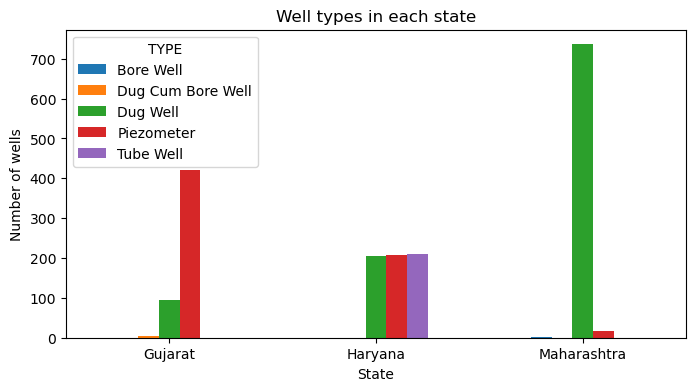

In [2]:
print(df["State"].value_counts())
print()
print(df["TYPE"].value_counts())

pd.crosstab(df["State"], df["TYPE"]).plot(kind="bar", figsize=(8, 4))
plt.title("Well types in each state")
plt.ylabel("Number of wells")
plt.xticks(rotation=0)
plt.show()

In [3]:
# Aquifer: look at how it is spread across states
pd.crosstab(df["Aquifer"], df["State"])

State,Gujarat,Haryana,Maharashtra
Aquifer,,,
ALLUVIUM,0,0,1
Aeolian Alluvium (Silt/ Sand) & Hard Formation,0,51,0
Alluvium,0,0,14
BASALT,0,0,59
Basalt,0,0,681
Confined I,98,0,0
Confined II,59,0,0
Confined III,9,0,0
Unconfined,351,0,0


**What to say:** *Aquifer names are different in every state (for example 'Basalt' appears only in Maharashtra). So Aquifer would only repeat the State information, and I will not use it as a feature.*

## Step 3: Fix the text readings
**What to say:** *Some 2022 readings are words, not numbers. 'Dry' means the water fell below the bottom of the well, which is the worst case, so I replace it with the well depth and remember it in a separate column. Other words (damaged, filled up, abandoned) mean no measurement was possible, so they become missing values.*

In [4]:
# Well depth must be a number; fill the few blanks with the median
df["Well_Depth (meters)"] = pd.to_numeric(df["Well_Depth (meters)"], errors="coerce")
df["Well_Depth (meters)"] = df["Well_Depth (meters)"].fillna(df["Well_Depth (meters)"].median())

# Remember which wells went dry in 2022
df["dry_2022"] = (df["Pre_2022"].astype(str).str.lower() == "dry") | (df["Post_2022"].astype(str).str.lower() == "dry")

# Convert every reading to a number
for col in reading_cols:
    is_dry = df[col].astype(str).str.lower() == "dry"       # find the Dry rows first
    df[col] = pd.to_numeric(df[col], errors="coerce")        # other words become missing (NaN)
    df.loc[is_dry, col] = df.loc[is_dry, "Well_Depth (meters)"]   # Dry -> well depth

print("Wells that went dry in 2022:", df["dry_2022"].sum())

Wells that went dry in 2022: 25


## Step 4: Explore the numeric variables
**What to say:** *For numbers I check the average, spread, minimum and maximum, and draw graphs. The depth values are skewed: most wells are shallow, but a few are very deep.*

In [5]:
df[["Latitude", "Longitude", "Well_Depth (meters)", "Pre_2021", "Pre_2022"]].describe().round(2)

,Latitude,Longitude,Well_Depth (meters),Pre_2021,Pre_2022
count,1896.00,1896.00,1896.00,1630.00,1852.00
mean,23.58,74.92,54.46,28.77,27.32
std,4.34,2.13,55.91,32.12,31.82
min,16.75,69.03,4.60,0.50,0.59
25%,19.60,72.88,13.30,8.30,7.30
50%,23.51,75.32,30.00,14.35,13.30
75%,28.30,76.60,81.37,38.48,36.58
max,30.45,78.76,457.00,195.41,200.00


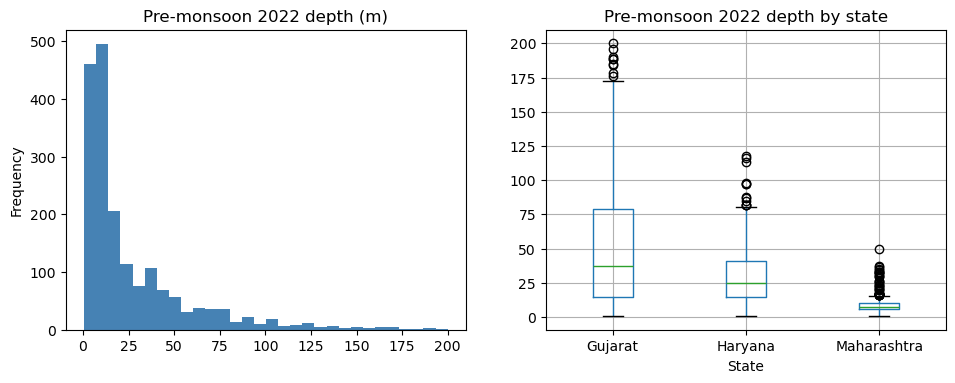

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["Pre_2022"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Pre-monsoon 2022 depth (m)")

df.boxplot(column="Pre_2022", by="State", ax=axes[1])
axes[1].set_title("Pre-monsoon 2022 depth by state")

plt.suptitle("")
plt.show()

## Step 5: Check for impossible values
**What to say:** *Water cannot be deeper than the well itself. I count readings that are more than 5 metres deeper than the well and treat them as data-entry errors (set to missing).*

In [7]:
errors = 0
for col in reading_cols:
    too_deep = df[col] > df["Well_Depth (meters)"] + 5
    errors = errors + too_deep.sum()
    df[col] = df[col].where(~too_deep)          # replace the impossible value with missing

print("Impossible readings found:", errors)
print("Negative readings:", (df[reading_cols] < 0).sum().sum())

Impossible readings found: 1
Negative readings: 0


## Step 6: Missing values
**What to say:** *First I see how much is missing in each reading column. Then I handle it in two steps. Wells without a real 2022 reading are removed, because 2022 is the value we will predict and I do not want to predict a guess. For small gaps in 2015-2021, I fill each value from the readings just before and after it, because water levels change gradually.*

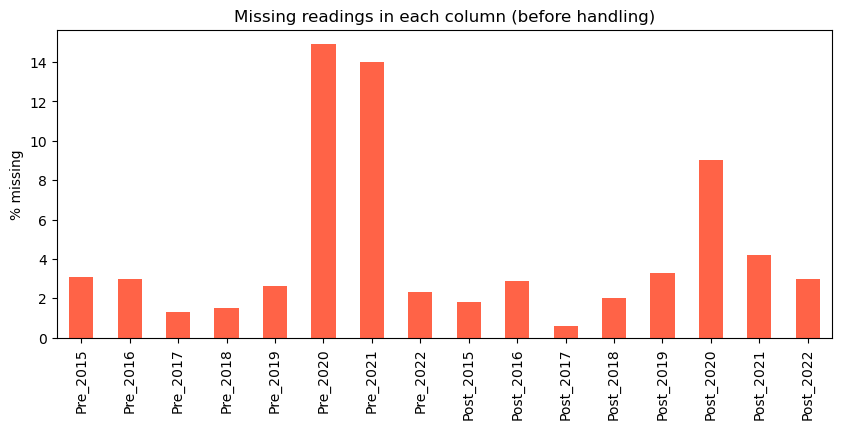

Total missing readings: 1320


In [8]:
missing_percent = df[reading_cols].isnull().mean() * 100
missing_percent.round(1).plot(kind="bar", figsize=(10, 4), color="tomato")
plt.ylabel("% missing")
plt.title("Missing readings in each column (before handling)")
plt.show()

print("Total missing readings:", df[reading_cols].isnull().sum().sum())

In [9]:
old_cols = pre_cols[:-1] + post_cols[:-1]            # the 14 readings from 2015 to 2021

# 1. keep only wells with a real 2022 pre-monsoon reading
df = df[df["Pre_2022"].notna()].copy()

# 2. keep only wells with at least half of the 2015-2021 readings
df = df[df[old_cols].notna().sum(axis=1) >= 7].copy()

# 3. fill the remaining gaps using the neighbouring years of the same well
df[old_cols] = df[old_cols].interpolate(axis=1, limit_direction="both")

print("Wells kept:", len(df))
print("Missing in 2015-2021 after filling:", df[old_cols].isnull().sum().sum())

Wells kept: 1848
Missing in 2015-2021 after filling: 0


## Step 7: Look at the cleaned data
**What to say:** *This graph shows the average pre-monsoon depth in each state over the years. The lines going down mean the water is getting deeper.*

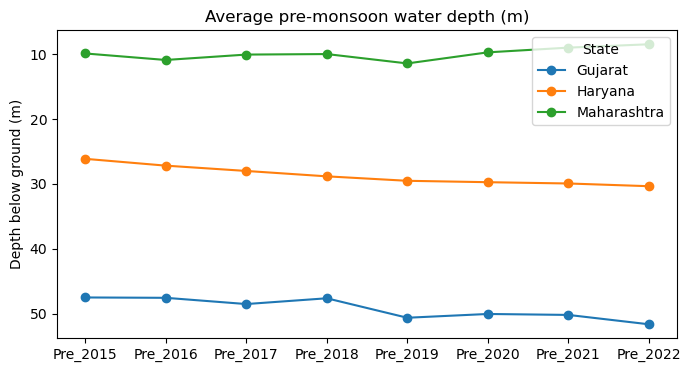

In [10]:
df.groupby("State")[pre_cols].mean().T.plot(marker="o", figsize=(8, 4))
plt.gca().invert_yaxis()                      # deeper water is lower on the graph
plt.title("Average pre-monsoon water depth (m)")
plt.ylabel("Depth below ground (m)")
plt.show()

## Step 8: Create new features
**What to say:** *From the 2015-2021 readings I build simple numbers that describe each well. I keep 2022 only as the value to predict, so the models never see the answer.*

In [11]:
df["pre_mean"] = df[pre_cols[:-1]].mean(axis=1)        # average pre-monsoon depth, 2015-2021
df["post_mean"] = df[post_cols[:-1]].mean(axis=1)      # average post-monsoon depth, 2015-2021
df["recharge"] = df["pre_mean"] - df["post_mean"]      # how much the water recovers after the monsoon
df["change"] = df["Pre_2021"] - df["Pre_2015"]         # how much deeper the water got in 6 years

df["target_2022"] = df["Pre_2022"]                     # the value we will predict

df[["pre_mean", "post_mean", "recharge", "change", "target_2022"]].describe().round(2)

,pre_mean,post_mean,recharge,change,target_2022
count,1848.00,1848.00,1848.00,1848.00,1848.00
mean,26.65,23.98,2.67,1.63,27.35
std,29.79,30.16,3.21,7.06,31.85
min,0.78,0.16,-8.64,-65.30,0.59
25%,8.90,4.54,0.29,-1.25,7.30
50%,13.64,10.74,1.97,0.70,13.35
75%,34.80,34.37,4.59,3.72,36.60
max,189.20,186.22,45.32,124.14,200.00


## Step 9: Normalisation (scaling)
**What to say:** *Features have very different sizes: latitude is about 25, but depth can reach 400. Models that use distances (KNN, SVM, K-Means) would be dominated by the large numbers. Scaling puts every feature on a similar scale. Standardisation gives mean 0 and standard deviation 1. Min-Max scaling squeezes values between 0 and 1.*

In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

num_cols = ["Latitude", "Longitude", "Well_Depth (meters)", "pre_mean", "post_mean", "recharge", "change"]

standard = pd.DataFrame(StandardScaler().fit_transform(df[num_cols]), columns=num_cols)
minmax = pd.DataFrame(MinMaxScaler().fit_transform(df[num_cols]), columns=num_cols)

print("Original:")
print(df[num_cols].describe().loc[["mean", "std", "min", "max"]].round(2))
print()
print("After standardisation:")
print(standard.describe().loc[["mean", "std", "min", "max"]].round(2))
print()
print("After min-max scaling:")
print(minmax.describe().loc[["mean", "std", "min", "max"]].round(2))

Original:
      Latitude  Longitude  Well_Depth (meters)  pre_mean  post_mean  recharge  \
mean     23.60      74.95                 53.6     26.65      23.98      2.67   
std       4.35       2.12                 54.4     29.79      30.16      3.21   
min      16.75      69.03                  4.6      0.78       0.16     -8.64   
max      30.45      78.76                457.0    189.20     186.22     45.32   

      change  
mean    1.63  
std     7.06  
min   -65.30  
max   124.14  

After standardisation:
      Latitude  Longitude  Well_Depth (meters)  pre_mean  post_mean  recharge  \
mean     -0.00       -0.0                -0.00     -0.00       0.00      0.00   
std       1.00        1.0                 1.00      1.00       1.00      1.00   
min      -1.58       -2.8                -0.90     -0.87      -0.79     -3.53   
max       1.57        1.8                 7.42      5.46       5.38     13.30   

      change  
mean    0.00  
std     1.00  
min    -9.48  
max    17.36  

Aft

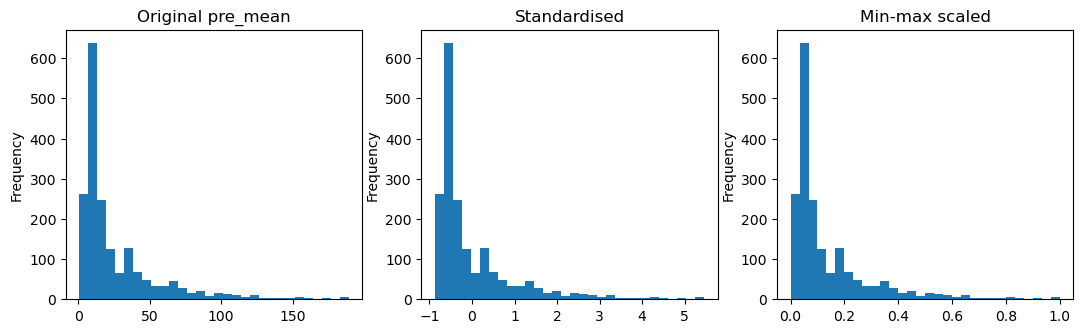

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df["pre_mean"].plot(kind="hist", bins=30, ax=axes[0], title="Original pre_mean")
standard["pre_mean"].plot(kind="hist", bins=30, ax=axes[1], title="Standardised")
minmax["pre_mean"].plot(kind="hist", bins=30, ax=axes[2], title="Min-max scaled")
plt.show()

**What to say:** *The shape of the distribution stays the same; only the scale changes. In the models, I will fit the scaler on the training wells only and then apply it to the test wells, so no information from the test set leaks into training.*

## Step 10: Encoding categorical variables
**What to say:** *Models need numbers, not text. One-hot encoding turns each category into its own 0/1 column.*

In [14]:
encoded = pd.get_dummies(df[["State", "TYPE"]], dtype=int)
print(encoded.columns.tolist())
encoded.head()

['State_Gujarat', 'State_Haryana', 'State_Maharashtra', 'TYPE_Bore Well', 'TYPE_Dug Cum Bore Well', 'TYPE_Dug Well', 'TYPE_Piezometer', 'TYPE_Tube Well']


,State_Gujarat,State_Haryana,State_Maharashtra,TYPE_Bore Well,TYPE_Dug Cum Bore Well,TYPE_Dug Well,TYPE_Piezometer,TYPE_Tube Well
0,1,0,0,0,0,0,1,0
1,1,0,0,0,0,0,1,0
2,1,0,0,0,0,0,1,0
3,1,0,0,0,0,0,1,0
4,1,0,0,0,0,1,0,0


## Step 11: Save the clean data
**What to say:** *The clean table holds one row per well with the cleaned readings, the new features, and the 2022 target. Practical 3 starts from this file.*

In [15]:
columns_to_keep = (["Well_ID", "State", "District", "TYPE", "Latitude", "Longitude", "Well_Depth (meters)"]
                   + reading_cols
                   + ["pre_mean", "post_mean", "recharge", "change", "target_2022", "dry_2022"])

df[columns_to_keep].to_csv("02_clean_wells.csv", index=False)

print("Saved 02_clean_wells.csv")
print("Wells:", len(df), "| Districts:", df["District"].nunique(), "| States:", df["State"].nunique())

Saved 02_clean_wells.csv
Wells: 1848 | Districts: 33 | States: 3


---
**Next: Practical 3 (Regression Modelling)**: risk classes, Simple / Multiple / Polynomial regression, OLS, correlations and Logistic Regression, starting from `02_clean_wells.csv`.